# ¿Puede un modelo reconocer la satisfacción leyendo una reseña?
**Sesión 3 · Procesamiento del Lenguaje Natural**

## Comparación de TF-IDF, SimpleRNN, LSTM, GRU y BiLSTM con Amazon Reviews en español

**Este notebook utiliza reseñas reales publicadas en un dataset, no textos sintéticos.**
El objetivo es predecir la calificación de **1 a 5 estrellas** que acompaña una reseña.
Compararemos calidad de predicción, errores y tiempo de entrenamiento para decidir si
una arquitectura más compleja aporta una mejora en este experimento.

La idea que queremos demostrar es sencilla: las palabras contienen señales de satisfacción,
pero interpretarlas exige atender a negaciones, contrastes y aspectos diferentes. Una
reseña puede elogiar el producto y criticar la entrega. Las estrellas resumen la valoración
de su autor y no describen perfectamente cada frase.

**Preguntas del laboratorio**
1. ¿Qué modelo clasifica mejor las cinco calificaciones?
2. ¿Confunde más las valoraciones intermedias que los extremos?
3. ¿Cómo cambia el desempeño con la longitud y la presencia de negaciones?
4. ¿Cuánto cuesta entrenar cada alternativa y qué errores siguen sin resolverse?

El resultado esperado es una comparación honesta, no demostrar de antemano que gana una red.


## Abrir y ejecutar: un solo archivo

**No hay que subir datos, copiar módulos ni clonar el repositorio para usar Colab.**
Abra este notebook y seleccione **Entorno de ejecución → Ejecutar todas** en Colab,
o **Run All** en VS Code. Espere a que finalice el entrenamiento.

El propio notebook prepara librerías, descarga aproximadamente 46 MB de reseñas reales
de una revisión fija de Hugging Face y verifica sus huellas. Requiere conexión a internet
para la primera ejecución y permisos para instalar librerías si faltan. En VS Code
necesita Python y las extensiones Python/Jupyter, con un kernel seleccionado.

Los datos y resultados quedan en `amazon_reviews_es/`, junto al directorio de trabajo.
En Colab los archivos temporales desaparecen al finalizar la sesión; descargue el notebook
ejecutado para conservar tablas y gráficos. La ejecución puede tardar varios minutos.
Si vuelve a ejecutar desde el principio en una sesión ya usada, reinicie primero el kernel.

Los dos bloques de funciones siguientes están integrados en este archivo. Puede leerlos
o mantenerlos plegados: la explicación de datos y modelos continúa debajo.


## Ruta de trabajo y auditoría de la Sesión 3

**Propósito:** comparar representaciones y redes para estimar una única calificación de 1 a 5 estrellas a partir de una reseña real en español. No inferimos causas, emociones anotadas ni intención política.

| Etapa | Qué revisar o realizar | Evidencia y decisión |
|---|---|---|
| 1. Procedencia | Fuente, revisión fija, hashes y significado de estrellas | Descarga verificable; no sustituir fallos por datos inventados |
| 2. Calidad | Esquema, nulos, etiquetas 0–4 y textos vacíos | Detener ante esquema/etiquetas inválidas; retirar vacíos y registrarlos |
| 3. Integridad | IDs, textos repetidos y etiquetas contradictorias | Retirar conflictos y copias; verificar ausencia de cruces exactos |
| 4. Exploración | Clases, longitudes y menciones de estrellas | Describir sesgos y mantener negaciones; no confundir muestra con población |
| 5. Separación | Train / validación / test | Aprender vocabulario solo en train; seleccionar con validación |
| 6. Representación | TF-IDF frente a IDs + embeddings | Medir cobertura, OOV, PAD y pérdida por truncamiento |
| 7. Modelado | SimpleRNN, LSTM, GRU y BiLSTM | Mismo corpus y presupuesto declarado; salida many-to-one |
| 8. Evaluación | F1 macro, precisión, recall, accuracy, log loss, MAE y costo | Comparar con baseline; examinar clases, curvas y fallos |
| 9. Robustez y cierre | Perturbaciones controladas, subconjuntos y recarga | Distinguir controles técnicos de generalización; declarar límites |

**Orden de lectura:** las funciones iniciales contienen la implementación reutilizable. Las secciones numeradas explican las decisiones y sus resultados. Las demostraciones posteriores al entrenamiento inspeccionan los modelos realmente entrenados, sin sustituir la evaluación.


In [1]:
# Este bloque instala únicamente las librerías ausentes o fuera del rango compatible.
# No requiere requirements.txt ni módulos del repositorio.
import sys, subprocess, importlib.util, importlib.metadata
from pathlib import Path
if not (3, 10) <= sys.version_info[:2] <= (3, 13):
    raise RuntimeError('Utilice un kernel Python 3.10 a 3.13; se verificó con 3.11.')
from packaging.specifiers import SpecifierSet
requisitos = {
    'numpy': '>=1.26,<3', 'pandas': '>=2.2,<4', 'matplotlib': '>=3.8,<4',
    'scikit-learn': '>=1.5,<2', 'tensorflow': '>=2.16,<2.22',
    'requests': '>=2.32,<3', 'joblib': '>=1.4,<2', 'urllib3': '>=2,<3'}
faltantes = []
for paquete, rango in requisitos.items():
    try:
        if importlib.metadata.version(paquete) not in SpecifierSet(rango):
            faltantes.append(paquete + rango)
    except importlib.metadata.PackageNotFoundError:
        faltantes.append(paquete + rango)
if faltantes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *faltantes])
    importlib.invalidate_caches()
    # Colab puede tener módulos precargados: no continuar con binarios de otra versión.
    for nombre in ['numpy', 'pandas', 'matplotlib']:
        modulo = sys.modules.get(nombre)
        if modulo is not None and getattr(modulo, '__version__', None) != importlib.metadata.version(nombre):
            raise RuntimeError('Se actualizaron librerías precargadas. Reinicie el kernel/sesión y vuelva a Ejecutar todo.')
ROOT = Path.cwd() / 'amazon_reviews_es'
ROOT.mkdir(exist_ok=True)
print('Preparación completada. Los datos y resultados se guardarán en:', ROOT)


Preparación completada. Los datos y resultados se guardarán en: C:\Users\User\Desktop\EAN\Sesion_3\NLP_3\prueba_autonomo\amazon_reviews_es


### Funciones de preparación de datos
Incluidas aquí para que el notebook sea independiente. Las etiquetas y la limpieza se explican en las secciones siguientes.

In [2]:
FUENTE_FIJADA = {'repositorio': 'SetFit/amazon_reviews_multi_es', 'revision': '16015418b488c9186fce74b058877ea939ca934d', 'descarga_utc': '2026-11-11T17:50:26.530514+00:00', 'datos_reales': True, 'archivos': {'README.md': {'url': 'https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/16015418b488c9186fce74b058877ea939ca934d/README.md', 'sha256': '5ec7747ab15dd3e352877e4d196627070ac5967b9ef3db82be9ddc14273666c9', 'bytes': 310}, 'create_dataset.py': {'url': 'https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/16015418b488c9186fce74b058877ea939ca934d/create_dataset.py', 'sha256': '3b1b3d7ca4be9e77f122fd64b85654bbc5ee30c8bcd2265709cb479635209e88', 'bytes': 644}, 'train.jsonl': {'url': 'https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/16015418b488c9186fce74b058877ea939ca934d/train.jsonl', 'sha256': 'f5ea8ef25c01e8eb51cc60d732cc9341e976c7910aab52c471fecab36465a8a1', 'bytes': 43777905}, 'validation.jsonl': {'url': 'https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/16015418b488c9186fce74b058877ea939ca934d/validation.jsonl', 'sha256': '62fe25433b7a63a8952b63246b3c4db20e2902cca4c6e2d20310dda736b71dce', 'bytes': 1088600}, 'test.jsonl': {'url': 'https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es/resolve/16015418b488c9186fce74b058877ea939ca934d/test.jsonl', 'sha256': 'aad4f1ce71f2235bf08ce1531ecc41cde7d6e55afa9b2aee83f90f3c2de0942a', 'bytes': 1097228}}}

"""Corpus real Amazon Reviews ES: descarga versionada y auditoría reproducible."""
from pathlib import Path
import hashlib
import gzip
import json
import re
import unicodedata
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from sklearn.model_selection import train_test_split

# ROOT se define en la primera celda; no depende de archivos Python externos.
DATA=ROOT/'datos_amazon'
REPO='SetFit/amazon_reviews_multi_es'

def limpiar(texto):
    """Preserva negación, tildes y términos de satisfacción; no elimina stopwords.

    No se quitan referencias explícitas a estrellas: forman parte de reseñas reales.
    Su frecuencia se audita porque pueden facilitar la predicción de la etiqueta.
    """
    t=unicodedata.normalize('NFKC',str(texto)).lower()
    t=re.sub(r'https?://\S+|www\.\S+',' ',t)
    t=re.sub(r'<[^>]+>',' ',t)
    return ' '.join(re.sub(r'[^\w\sáéíóúüñ]',' ',t).split())

def descargar():
    """Sin generación artificial ni ejecución de scripts remotos; archivos JSONL.

    La primera descarga fija revisión y hashes. Ejecuciones posteriores comprueban
    los archivos locales para evitar cambiar silenciosamente el corpus.
    """
    DATA.mkdir(exist_ok=True)
    manifest=DATA/'procedencia.json'
    if manifest.exists():
        meta=json.loads(manifest.read_text(encoding='utf-8'))
        for name,record in meta['archivos'].items():
            path=DATA/name
            compressed=path.with_suffix(path.suffix+'.gz')
            content=(path.read_bytes() if path.exists() else
                     gzip.decompress(compressed.read_bytes()) if compressed.exists() else None)
            if content is None or hashlib.sha256(content).hexdigest()!=record['sha256']:
                raise ValueError(f'Archivo ausente o modificado: {path}; revise antes de reutilizar.')
        return meta
    session=requests.Session()
    session.mount('https://',HTTPAdapter(max_retries=Retry(total=4,backoff_factor=2,status_forcelist=[429,500,502,503])))
    expected=FUENTE_FIJADA
    revision=expected['revision']
    meta={'repositorio':REPO,'revision':revision,'descarga_utc':pd.Timestamp.now(tz='UTC').isoformat(),
          'datos_reales':True,'archivos':{}}
    for name in ['README.md','create_dataset.py','train.jsonl','validation.jsonl','test.jsonl']:
        url=f'https://huggingface.co/datasets/{REPO}/resolve/{revision}/{name}'
        print('Descargando',name,flush=True)
        response=session.get(url,timeout=(30,180)); response.raise_for_status()
        if name.endswith('.jsonl') and 'text/html' in response.headers.get('Content-Type',''):
            raise ValueError('Se recibió HTML en lugar del dataset.')
        digest=hashlib.sha256(response.content).hexdigest()
        if expected and digest!=expected['archivos'][name]['sha256']:
            raise ValueError(f'La huella descargada no coincide: {name}')
        (DATA/name).write_bytes(response.content)
        meta['archivos'][name]={'url':url,'sha256':hashlib.sha256(response.content).hexdigest(),'bytes':len(response.content)}
    manifest.write_text(json.dumps(meta,ensure_ascii=False,indent=2),encoding='utf-8')
    return meta

def preparar(n_train=20000,seed=42):
    """Respeta splits oficiales; elimina duplicados y conflictos antes del muestreo.

    Se revisan duplicados exactos tras normalizar. Sin ID de producto/autor en esta
    versión, no puede garantizarse separación por producto ni detectar paráfrasis.
    """
    meta=descargar(); frames=[]
    for split in ['train','validation','test']:
        path=DATA/f'{split}.jsonl'
        if not path.exists(): path=path.with_suffix('.jsonl.gz')
        d=pd.read_json(path,lines=True)
        if not {'id','text','label'}<=set(d.columns): raise ValueError('Esquema de origen inesperado.')
        d=d[['id','text','label']].copy(); d['split']=split
        if d.isna().any().any(): raise ValueError('El origen contiene nulos.')
        if not d.label.isin(range(5)).all(): raise ValueError('Etiquetas inesperadas.')
        d['texto_limpio']=d.text.map(limpiar)
        frames.append(d)
    all_data=pd.concat(frames,ignore_index=True)
    original=all_data.groupby('split').size().to_dict()
    # Una misma cadena con calificaciones distintas es ambigua para este experimento.
    conflicts=all_data.groupby('texto_limpio').label.nunique()
    bad=set(conflicts[conflicts>1].index)
    empty=all_data.texto_limpio.eq('')
    conflict_count=int(all_data.texto_limpio.isin(bad).sum())
    clean=all_data[~empty & ~all_data.texto_limpio.isin(bad)].copy()
    before=len(clean)
    # Orden estable: se conserva train primero; copias en val/test quedan excluidas.
    clean=clean.drop_duplicates('texto_limpio').drop_duplicates('id')
    dedup_removed=before-len(clean)
    parts={s:clean[clean.split.eq(s)].copy() for s in ['train','validation','test']}
    train=parts['train']
    if n_train<len(train):
        _,train=train_test_split(train,test_size=n_train,stratify=train.label,random_state=seed)
    train=train.sort_values('id').reset_index(drop=True)
    val=parts['validation'].reset_index(drop=True); test=parts['test'].reset_index(drop=True)
    for d in [train,val,test]:
        if set(d.label)!=set(range(5)): raise ValueError('Una partición no tiene las cinco clases.')
        d['estrellas']=d.label+1
        d['n_palabras']=d.texto_limpio.str.split().str.len()
    for a,b in [(train,val),(train,test),(val,test)]:
        assert not set(a.id)&set(b.id)
        assert not set(a.texto_limpio)&set(b.texto_limpio)
    audit={'originales':original,'filas_vacias':int(empty.sum()),'filas_con_etiquetas_en_conflicto':conflict_count,
           'duplicados_retirados':dedup_removed,'tras_limpieza':clean.groupby('split').size().to_dict(),
           'utilizados':dict(train=len(train),validation=len(val),test=len(test)),
           'semilla':seed,'mencion_estrellas_train':float(train.texto_limpio.str.contains(r'\bestrellas?\b').mean())}
    (DATA/'auditoria.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
    return train,val,test,meta,audit



### Funciones de entrenamiento y evaluación
Implementan los cinco modelos descritos más adelante. No descargan ni ejecutan código externo.

In [3]:
"""Cinco modelos para predecir estrellas de reseñas reales, con evaluación separada."""
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_recall_fscore_support,log_loss,
                             mean_absolute_error,classification_report,ConfusionMatrixDisplay)
from sklearn.pipeline import make_pipeline

def iniciar(seed=42):
    """Ejecución local reproducible; sin complementos de aceleración."""
    import tensorflow as tf
    tf.config.set_visible_devices([], 'GPU')
    tf.keras.utils.set_random_seed(seed)
    return {'tensorflow':tf.__version__,'semilla':seed,'dispositivo':'CPU'}

def medir(y,prob):
    """MAE añade el tamaño del error: confundir 1 con 5 es peor que 4 con 5."""
    pred=prob.argmax(1)
    precision,recall,f1,_=precision_recall_fscore_support(y,pred,labels=range(5),average='macro',zero_division=0)
    return dict(accuracy=accuracy_score(y,pred),precision_macro=precision,recall_macro=recall,
                f1_macro=f1,log_loss=log_loss(y,prob,labels=list(range(5))),
                mae_estrellas=mean_absolute_error(y,pred),error_dos_o_mas=float((np.abs(np.asarray(y)-pred)>=2).mean()))

def entrenar(train,val,test,out,epochs=8,batch=128,units=32):
    """Selección por F1 de validación, seguida de una comparación final en test.

    Un mismo corpus y presupuesto recurrente facilitan la comparación. El baseline
    prueba dos regularizaciones; esto no es una búsqueda exhaustiva ni equidad de
    costo computacional. La comparación documenta un experimento concreto.
    """
    import tensorflow as tf
    out=Path(out); out.mkdir(exist_ok=True,parents=True)
    val_rows=[]; costos=[]; models={}
    for name,part in [('train',train),('validation',val),('test',test)]:
        part.to_csv(out/f'particion_{name}.csv',index=False)
    # TF-IDF aprende exclusivamente del conjunto de entrenamiento; incluye negaciones.
    start=time.perf_counter(); best_score=-1
    for c in [.5,2.0]:
        baseline=make_pipeline(TfidfVectorizer(ngram_range=(1,2),min_df=2,
                                max_features=30000,sublinear_tf=True,token_pattern=r'(?u)\b\w+\b'),
                               LogisticRegression(C=c,max_iter=500,random_state=42))
        baseline.fit(train.texto_limpio,train.label)
        metrics=medir(val.label,baseline.predict_proba(val.texto_limpio))
        if metrics['f1_macro']>best_score:
            best_score=metrics['f1_macro']; best=baseline; best_c=c; best_metrics=metrics
    joblib.dump(best,out/'tfidf.joblib'); models['tfidf']=best
    val_rows.append(dict(modelo='tfidf',**best_metrics))
    costos.append(dict(modelo='tfidf',segundos_entrenamiento=time.perf_counter()-start,
                       parametros=best[-1].coef_.size+best[-1].intercept_.size,epocas=0))
    print('Baseline ajustado; C seleccionado:',best_c,flush=True)
    # Percentil calculado solo con train. El límite controla el costo en el equipo local.
    length=int(np.clip(np.percentile(train.n_palabras,95),16,96))
    vector=tf.keras.layers.TextVectorization(max_tokens=15000,standardize=None,output_sequence_length=length)
    vector.adapt(tf.data.Dataset.from_tensor_slices(train.texto_limpio.to_numpy(dtype=str)).batch(batch))
    xs=[vector(tf.constant(d.texto_limpio.to_list())) for d in [train,val,test]]
    ys=[d.label.to_numpy(dtype=np.int32) for d in [train,val,test]]
    vocab=vector.get_vocabulary()
    (out/'vocabulario.json').write_text(json.dumps(vocab,ensure_ascii=False),encoding='utf-8')
    cfg={'longitud':length,'vocabulario':len(vocab),'embedding':32,'units':units,'batch':batch,
         'epocas_maximas':epochs,'C_baseline':best_c,'etiquetas':{i:i+1 for i in range(5)},
         'truncamiento':{name:float((d.n_palabras>length).mean()) for name,d in [('train',train),('val',val),('test',test)]}}
    (out/'configuracion.json').write_text(json.dumps(cfg,indent=2),encoding='utf-8')
    def dataset(i,shuffle=False):
        d=tf.data.Dataset.from_tensor_slices((xs[i],ys[i]))
        if shuffle: d=d.shuffle(len(train),seed=42)
        return d.batch(batch).prefetch(tf.data.AUTOTUNE)
    for name in ['rnn','lstm','gru','bilstm']:
        print('Entrenando',name,flush=True); tf.keras.utils.set_random_seed(42)
        inp=tf.keras.Input((length,),dtype='int64')
        x=tf.keras.layers.Embedding(len(vocab),32,mask_zero=True)(inp)
        cls={'rnn':tf.keras.layers.SimpleRNN,'lstm':tf.keras.layers.LSTM,'gru':tf.keras.layers.GRU,'bilstm':tf.keras.layers.LSTM}[name]
        recurrent=cls(units)
        x=(tf.keras.layers.Bidirectional(recurrent) if name=='bilstm' else recurrent)(x)
        x=tf.keras.layers.Dropout(.25)(x)
        outputs=tf.keras.layers.Dense(5,activation='softmax')(x)
        model=tf.keras.Model(inp,outputs,name=name)
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-3,clipnorm=1),
                      loss='sparse_categorical_crossentropy',metrics=['accuracy'])
        start=time.perf_counter()
        hist=model.fit(dataset(0,True),validation_data=dataset(1),epochs=epochs,verbose=0,shuffle=False,
                       callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=True),
                                  tf.keras.callbacks.TerminateOnNaN()])
        elapsed=time.perf_counter()-start
        if not np.isfinite(hist.history['loss']).all(): raise RuntimeError('Entrenamiento no finito.')
        model.save(out/f'{name}.keras'); models[name]=model
        pd.DataFrame(hist.history).to_csv(out/f'historia_{name}.csv',index=False)
        fig,ax=plt.subplots(1,2,figsize=(11,4))
        for a,metric,title in zip(ax,['loss','accuracy'],['Pérdida','Proporción de aciertos']):
            a.plot(range(1,len(hist.history[metric])+1),hist.history[metric],label='Train')
            a.plot(range(1,len(hist.history[metric])+1),hist.history['val_'+metric],label='Validación')
            a.set_title(title); a.set_xlabel('Época'); a.legend()
        fig.suptitle(name.upper()); fig.tight_layout(); fig.savefig(out/f'curvas_{name}.png'); plt.close(fig)
        costos.append(dict(modelo=name,segundos_entrenamiento=elapsed,parametros=model.count_params(),epocas=len(hist.history['loss'])))
        val_rows.append(dict(modelo=name,**medir(val.label,model.predict(xs[1],batch_size=batch,verbose=0))))
        print(name,'terminado:',len(hist.history['loss']),'épocas',flush=True)
    validacion=pd.DataFrame(val_rows)
    winner=validacion.sort_values('f1_macro',ascending=False).iloc[0].modelo
    validacion.to_csv(out/'validacion.csv',index=False)
    (out/'seleccion.json').write_text(json.dumps({'modelo':winner,'criterio':'F1 macro en validación'},ensure_ascii=False),encoding='utf-8')
    print('Selección cerrada:',winner,'; evaluando test.',flush=True)
    test_rows=[]; predicciones={}; segmentos=[]
    # Test se abre una vez que terminó la elección. No se reajusta con sus métricas.
    for name,model in models.items():
        prob=model.predict_proba(test.texto_limpio) if name=='tfidf' else model.predict(xs[2],batch_size=batch,verbose=0)
        pred=prob.argmax(1); test_rows.append(dict(modelo=name,**medir(test.label,prob)))
        p=test[['id','text','n_palabras','estrellas']].copy()
        p['prediccion']=pred+1; p['probabilidad_maxima']=prob.max(1)
        p['error_absoluto']=abs(p.estrellas-p.prediccion)
        p.to_csv(out/f'predicciones_{name}.csv',index=False); predicciones[name]=p
        # Errores graves y seguros: material para revisar, no prueba de calibración.
        p[p.error_absoluto>0].sort_values(['error_absoluto','probabilidad_maxima'],ascending=False).head(30).to_csv(out/f'errores_{name}.csv',index=False)
        pd.DataFrame(classification_report(test.label,pred,labels=range(5),target_names=[str(i)+' estrellas' for i in range(1,6)],output_dict=True,zero_division=0)).T.to_csv(out/f'reporte_{name}.csv')
        fig,ax=plt.subplots(figsize=(7,6))
        ConfusionMatrixDisplay.from_predictions(test.label+1,pred+1,labels=range(1,6),ax=ax,colorbar=False)
        ax.set_xlabel('Estrellas predichas'); ax.set_ylabel('Estrellas reales'); ax.set_title(name.upper())
        fig.tight_layout(); fig.savefig(out/f'matriz_{name}.png'); plt.close(fig)
        masks={'cortas_hasta_20':test.n_palabras<=20,'medias_21_a_60':test.n_palabras.between(21,60),
               'largas_mas_60':test.n_palabras>60,'con_negacion':test.texto_limpio.str.contains(r'\b(?:no|nunca|sin|jamás)\b'),
               'menciona_estrellas':test.texto_limpio.str.contains(r'\bestrellas?\b')}
        for seg,mask in masks.items():
            if mask.any():
                segmentos.append(dict(modelo=name,segmento=seg,n=int(mask.sum()),
                                       accuracy=accuracy_score(test.label[mask],pred[mask]),
                                       mae_estrellas=mean_absolute_error(test.label[mask],pred[mask])))
    report=pd.DataFrame(test_rows).merge(pd.DataFrame(costos),on='modelo')
    report.to_csv(out/'metricas_test.csv',index=False)
    pd.DataFrame(segmentos).to_csv(out/'segmentos.csv',index=False)
    # Referencia adicional: siempre predecir la clase más frecuente de train.
    majority=int(train.label.mode().iloc[0]); pred=np.full(len(test),majority)
    (out/'referencia_mayoritaria.json').write_text(json.dumps({'estrellas':majority+1,'accuracy':accuracy_score(test.label,pred)}),encoding='utf-8')
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    ax[0].bar(report.modelo,report.f1_macro); ax[0].set_title('F1 macro en test'); ax[0].set_ylim(0,1)
    ax[1].bar(report.modelo,report.segundos_entrenamiento); ax[1].set_title('Tiempo de entrenamiento'); ax[1].set_ylabel('Segundos')
    fig.tight_layout(); fig.savefig(out/'comparacion.png'); plt.close(fig)
    return report,validacion,predicciones

def predecir(textos,out,modelo=None):
    """Recarga los archivos guardados. El resultado es calificación estimada, no hechos."""
    out=Path(out); clean=[limpiar(t) for t in textos]
    if not clean or any(not t for t in clean): raise ValueError('Los textos no pueden estar vacíos.')
    modelo=modelo or json.loads((out/'seleccion.json').read_text(encoding='utf-8'))['modelo']
    if modelo=='tfidf': prob=joblib.load(out/'tfidf.joblib').predict_proba(clean)
    else:
        import tensorflow as tf
        cfg=json.loads((out/'configuracion.json').read_text())
        vector=tf.keras.layers.TextVectorization(standardize=None,output_sequence_length=cfg['longitud'])
        vector.set_vocabulary(json.loads((out/'vocabulario.json').read_text(encoding='utf-8')))
        model=tf.keras.models.load_model(out/f'{modelo}.keras')
        prob=model.predict(vector(tf.constant(clean)),verbose=0)
    return pd.DataFrame({'texto':textos,'estrellas_predichas':prob.argmax(1)+1,'probabilidad_maxima':prob.max(1)})


## 1. Qué datos usamos y qué representa una fila

Usamos [SetFit/amazon_reviews_multi_es](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es),
una versión del corpus multilingüe de reseñas de Amazon que conserva los textos en español.
La distribución publicada tiene 200.000 reseñas de entrenamiento, 5.000 de validación y
5.000 de prueba. Su script de preparación establece **label = estrellas − 1**.

| Campo original | Significado | Uso en este ejercicio |
|---|---|---|
| id | Identificador de reseña | Revisar duplicados y rastrear resultados |
| text | Texto original escrito por el cliente | Entrada del modelo después de limpiar |
| label | Calificación codificada de 0 a 4 | Objetivo que el modelo aprende |
| label_text | La misma etiqueta como texto | No se usa como entrada |

Los títulos, categorías de producto e identificadores de producto/autor no están presentes
en esta versión. Por tanto no podemos analizar categorías comerciales ni asegurar separación
por cliente o producto. **No hay etiquetas de causa de insatisfacción**: no inventaremos
«entrega», «precio» o «calidad» como respuestas conocidas.

La calificación fue dada por el usuario, no anotada como sentimiento por un lingüista.
Predecir estrellas es una aproximación útil a satisfacción, con ruido y ambigüedad.
La muestra tampoco representa automáticamente todos los clientes de Amazon.

Guardamos la revisión descargada, URL y huella de cada archivo para que el origen sea
verificable. Las siguientes ejecuciones en la misma sesión o carpeta usan esos mismos archivos. Una descarga fallida
detiene el ejercicio; nunca se sustituye por datos inventados.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

# Un tamaño moderado permite comparar las redes en el equipo local.
# Ocho épocas es el máximo; la parada temprana puede finalizar antes.
N_TRAIN = 20000
EPOCHS = 8
OUT = ROOT / 'resultados_amazon'
OUT.mkdir(exist_ok=True)
entorno = iniciar(seed=42)
train, val, test, procedencia, auditoria = preparar(n_train=N_TRAIN, seed=42)
(OUT / 'entorno.json').write_text(json.dumps(entorno, indent=2), encoding='utf-8')
display(Markdown(f"**Fuente:** `{procedencia['repositorio']}` · **revisión:** `{procedencia['revision']}`"))
display(train[['id','text','estrellas']].head(8))


**Fuente:** `SetFit/amazon_reviews_multi_es` · **revisión:** `16015418b488c9186fce74b058877ea939ca934d`

,id,text,estrellas
0,es_0000061,sabor y cálidad se diluye muy bien excelente r...,5
1,es_0000111,"No están mal, echo de menos el enchufe de corr...",4
2,es_0000148,Los rollos estan bien puedes adaptarlos al pro...,5
3,es_0000187,"compra fácil y rápida. Entrega igual, y el pro...",4
4,es_0000392,"Para una TV de 24"" como la mía de la marca Sam...",2
5,es_0000446,Muy malo se rompió enseguida no vale para nada,1
6,es_0000470,Estuve mirando horas y horas que lámpara compr...,5
7,es_0000491,"no funciona, perdida de tiempo y dinero",1


## 2. Auditoría: por qué no entrenamos directamente sobre todo el archivo

Las reseñas cortas pueden repetirse. Si el mismo texto aparece en entrenamiento y prueba,
el resultado puede reflejar memorización. Además, una cadena idéntica puede tener estrellas
distintas porque los autores valoran cosas diferentes. Para este experimento retiramos esas
cadenas ambiguas y las copias exactas después de normalizar. No significa que fueran opiniones
inválidas; es una decisión que simplifica el problema y debe declararse al interpretar resultados.

Conservamos la pertenencia a los conjuntos originales. Si hay copias entre conjuntos,
se conserva primero entrenamiento y se retiran de validación/prueba. Esta limpieza usa
las etiquetas únicamente para auditar conflictos, no para seleccionar modelos; modifica
el benchmark original y por eso nuestros números no son directamente comparables con él.

De entrenamiento seleccionamos 20.000 filas manteniendo aproximadamente la distribución
de las cinco clases. La semilla fija la muestra. La detección es de duplicados exactos,
no de paráfrasis ni de reseñas del mismo producto.


In [5]:
display(pd.DataFrame({
    'filas_originales': auditoria['originales'],
    'tras_limpieza': auditoria['tras_limpieza'],
    'usadas': auditoria['utilizados']}))
print('Filas con texto idéntico y etiquetas distintas retiradas:', auditoria['filas_con_etiquetas_en_conflicto'])
print('Copias adicionales retiradas:', auditoria['duplicados_retirados'])
print('Reseñas de train que mencionan estrella(s):', f"{auditoria['mencion_estrellas_train']:.1%}")
print('No hay textos exactos ni identificadores compartidos entre las particiones.')

print('Textos vacíos retirados:', auditoria['filas_vacias'])

,filas_originales,tras_limpieza,usadas
test,5000,4905,4905
train,200000,196946,20000
validation,5000,4905,4905


Filas con texto idéntico y etiquetas distintas retiradas: 2573
Copias adicionales retiradas: 671
Reseñas de train que mencionan estrella(s): 2.0%
No hay textos exactos ni identificadores compartidos entre las particiones.
Textos vacíos retirados: 0


## 3. Explorar antes de modelar

Una clase frecuente puede inflar accuracy sin que el modelo aprenda las otras. Revisamos
cuántas reseñas hay de cada calificación. También observamos las longitudes: ayudan a decidir
cuánto texto conservar y a entender si unas reseñas son más difíciles que otras.

Estas figuras describen el corpus utilizado, no la distribución natural de satisfacción
de los compradores. La selección del dataset afecta lo que podemos concluir.


,train,validacion,test
estrellas,,,
1,4023,983,989
2,4034,992,988
3,4012,982,987
4,3963,976,974
5,3968,972,967


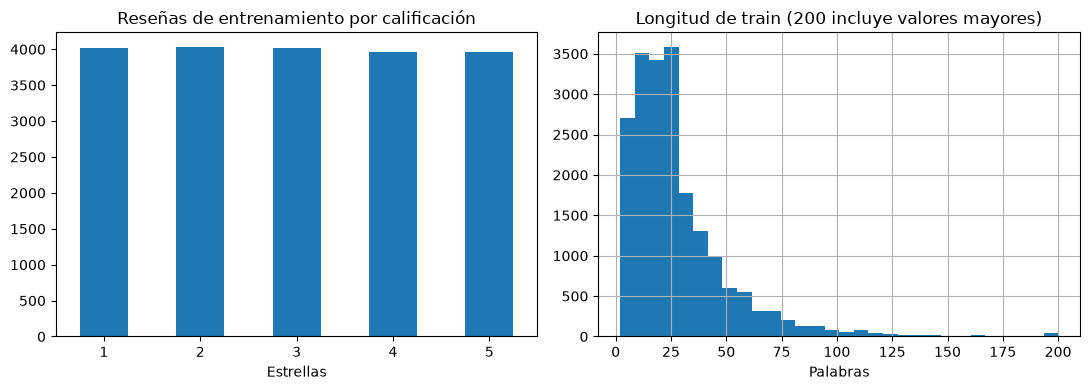

0.50     22.0
0.90     56.0
0.95     72.0
0.99    122.0
Name: palabras, dtype: float64

In [6]:
distribucion = pd.DataFrame({n:d.estrellas.value_counts().sort_index()
    for n,d in [('train',train),('validacion',val),('test',test)]})
display(distribucion)
fig, ax = plt.subplots(1,2,figsize=(11,4))
distribucion['train'].plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Reseñas de entrenamiento por calificación'); ax[0].set_xlabel('Estrellas')
train.n_palabras.clip(upper=200).hist(bins=30,ax=ax[1])
ax[1].set_title('Longitud de train (200 incluye valores mayores)'); ax[1].set_xlabel('Palabras')
plt.tight_layout(); plt.show()
display(train.n_palabras.quantile([.5,.9,.95,.99]).rename('palabras'))


## 4. Limpieza: conservar lo que cambia la opinión

Pasamos a minúsculas, normalizamos espacios y retiramos URL y marcas HTML. Conservamos
negaciones como «no», «nunca» y «sin», porque eliminarlas podría invertir la interpretación.
No se hace traducción ni se generan frases nuevas. Todos los ejemplos mostrados abajo
provienen de reseñas descargadas.

La limpieza pierde información de puntuación y emojis. Es una simplificación que puede
perjudicar la interpretación de ironía. También conservamos menciones explícitas a estrellas:
son parte del texto real, pero facilitan la tarea; mediremos ese subconjunto por separado.


In [7]:
display(train[['text','texto_limpio']].head(5))
assert limpiar('No funciona') == 'no funciona'


,text,texto_limpio
0,sabor y cálidad se diluye muy bien excelente r...,sabor y cálidad se diluye muy bien excelente r...
1,"No están mal, echo de menos el enchufe de corr...",no están mal echo de menos el enchufe de corri...
2,Los rollos estan bien puedes adaptarlos al pro...,los rollos estan bien puedes adaptarlos al pro...
3,"compra fácil y rápida. Entrega igual, y el pro...",compra fácil y rápida entrega igual y el produ...
4,"Para una TV de 24"" como la mía de la marca Sam...",para una tv de 24 como la mía de la marca sams...


## 5. Tres conjuntos con responsabilidades diferentes

- **Entrenamiento:** aprende vocabulario, representaciones y pesos.
- **Validación:** elige regularización, controla sobreajuste y selecciona modelo.
- **Prueba:** evalúa al final; sus resultados no se usan para retocar los modelos.

Los cinco modelos usan las mismas reseñas. El baseline prueba dos regularizaciones y las
redes comparten tamaño de embedding, unidades y límite de épocas. Esto permite comparar
un presupuesto concreto, no afirmar cuál arquitectura sería mejor con cualquier ajuste.

## 6. TF-IDF + regresión logística: la referencia

TF-IDF representa cada reseña mediante el peso de palabras y pares de palabras. Las
expresiones frecuentes en todas las reseñas suelen aportar menos que las que distinguen
opiniones. Los bigramas permiten representar «no funciona» como una unidad adicional.
La regresión logística aprende qué señales se asocian con cada calificación.

No es una predicción lineal del número de estrellas: aquí se usa como clasificación de
cinco categorías. Es una referencia fuerte y económica que las redes deben justificar superar.

## 7. Del texto a una secuencia: vocabulario y representaciones

### 7.1 Vocabulario: qué palabras conoce el modelo

El vocabulario es una tabla que asigna un entero a cada token. Se construye **solo con train** mediante `TextVectorization.adapt`. Aquí un token es una unidad separada por espacios después de limpiar. No usamos subpalabras ni un tokenizador preentrenado. Un ID es una dirección en una tabla: el 200 no tiene más sentimiento que el 20.

El límite es **15.000 posiciones**, incluyendo dos posiciones especiales. Por ello hay como máximo **14.998 palabras ordinarias**. Conservamos las más frecuentes de train; validación y test se transforman con ese vocabulario congelado.

### 7.2 PAD y OOV: dos símbolos con funciones diferentes

| Concepto | ID en este notebook | Qué representa | ¿Se procesa como contenido? |
|---|---|---|---|
| PAD | `0`, entrada `''` en el vocabulario | No hay palabra en esa posición | No: la máscara lo omite |
| OOV / UNK | `1`, entrada `[UNK]` | Sí hay palabra, pero no tiene entrada propia | Sí: usa el embedding compartido de desconocidos |
| Palabra conocida | `2` en adelante | Token aprendido de train | Sí |

**OOV** significa *out of vocabulary*: aparece con términos raros excluidos, marcas, erratas o palabras nuevas. Todas esas palabras comparten el ID 1 y pierden su identidad individual. No debemos convertir OOV en PAD: ocultaría palabras que sí estaban presentes. La tasa OOV se calcula sobre tokens reales, excluyendo relleno.

### 7.3 Padding y truncamiento

Los lotes requieren una longitud común `L`. **Padding** añade ceros al final de una reseña corta (*post-padding*). **Truncamiento** conserva los primeros `L` tokens y elimina los restantes (*post-truncation*). No son sinónimos: uno añade espacio vacío y el otro elimina contenido real.

`L = int(clip(percentil_95(longitudes_train), 16, 96))`. Esta regla se fija antes de consultar test; no promete conservar exactamente el 95% si intervienen los límites. Se informa la proporción de reseñas truncadas y la de tokens descartados. Una queja al final puede perderse, aunque el principio sea positivo. En la demostración se mostrarán una reseña corta, una larga y un OOV real, con sus IDs y máscara.

### 7.4 ¿Por qué no usar todas las palabras?

Hay dos decisiones distintas. **Limitar el vocabulario** reduce memoria, parámetros y estimaciones débiles de palabras muy raras; el costo es perder señales útiles en OOV. La tabla de embeddings cuesta `V × 32` pesos. **Limitar longitud** reduce pasos recurrentes y relleno; el costo es perder finales informativos. El costo recurrente crece con `L` y con el tamaño del estado. Estas restricciones no demuestran que más palabras empeoren: son un presupuesto del experimento. La tabla de cobertura permite cuantificar el compromiso; para elegir otro límite habría que comparar en validación.

No eliminamos todas las palabras comunes (*stopwords*). «No», «sin» y «pero» pueden cambiar una valoración; mantenerlas ayuda a representar negación y contraste. TF-IDF atenúa términos muy extendidos mediante IDF y usa bigramas; las redes reciben la secuencia completa hasta `L`.

### 7.5 Masking: señalar qué posiciones no cuentan

`Embedding(..., mask_zero=True)` genera una máscara booleana: `False` para ID 0 y `True` para tokens reales, incluido OOV. Keras propaga esa máscara a SimpleRNN/LSTM/GRU y a la capa bidireccional. El estado recurrente no debe incorporar los pasos de relleno.

**Masking no es borrar la fila 0 de la matriz ni garantizar un embedding numéricamente nulo.** Tampoco recupera palabras truncadas. Más adelante verificamos que agregar PAD a una misma secuencia no cambia la salida, dentro de tolerancia numérica. Esto comprueba el tratamiento del relleno, no la comprensión del lenguaje.

### 7.6 Embeddings entrenables

Una tabla `E` de forma `(V, 32)` transforma un lote de IDs `(B, L)` en vectores `(B, L, 32)`. Sus valores empiezan aleatorios; no tienen conocimiento previo del español. La pérdida de clasificación produce gradientes que ajustan la tabla junto con los pesos recurrentes. Las 32 dimensiones no corresponden a 32 emociones nombradas. Cada arquitectura entrena su propia tabla con sus propias señales.

Mostraremos la forma real, su condición `trainable` y un gradiente no nulo para embeddings en una minibatch real. Calculamos ese gradiente sin aplicar actualizaciones al modelo evaluado. La fila OOV solo aprenderá si recibe gradientes de ejemplos de train que contengan OOV; el PAD queda excluido del procesamiento recurrente.

## 8. Redes recurrentes y patrón de salida

### 8.1 SimpleRNN: una memoria que se actualiza palabra a palabra

Para el vector de palabra `x_t`, el estado es:

\[
h_t = \tanh(x_t W_x + h_{t-1} W_h + b).
\]

Los mismos pesos se reutilizan en cada paso. El estado resume lo leído; no guarda literalmente todas las palabras. Usamos **32 unidades**, y la capa densa transforma el estado final en cinco probabilidades. Con contextos largos, la retropropagación puede producir gradientes muy pequeños o grandes. `clipnorm=1` limita explosiones, pero no resuelve por sí solo el olvido de información distante.

### 8.2 LSTM, GRU y BiLSTM: qué cambia en la memoria

| Modelo | Mecanismo | Estado que llega al clasificador | Compromiso |
|---|---|---|---|
| SimpleRNN | Una actualización tanh | 32 valores | Sencilla; dificultades con dependencias largas |
| LSTM | Estado de celda y compuertas de entrada, olvido y salida | 32 valores | Más parámetros para regular información a lo largo de la secuencia |
| GRU | Compuertas de actualización y reinicio | 32 valores | Menos componentes que LSTM; el costo real se mide |
| BiLSTM | Dos LSTM, hacia adelante y hacia atrás | 64 valores concatenados | Usa contexto de ambos sentidos; mayor costo |

Las compuertas no garantizan ganar al baseline. BiLSTM necesita disponer del texto completo y no corresponde a una lectura causal palabra a palabra en tiempo real. TF-IDF no mantiene un estado recurrente, pero los bigramas recogen parte del orden local. Comparamos F1 macro, errores, tiempos y pesos; no solo accuracy.

### 8.3 ¿Many-to-one, many-to-many alineado o sequence-to-sequence?

**Nuestro problema es MANY-TO-ONE: muchas palabras → una calificación por reseña.** Las cinco probabilidades son alternativas de una sola variable, no cinco pasos de salida. Las redes usan `return_sequences=False` (valor predeterminado).

| Patrón | Entrada → salida | Ejemplo | ¿Es este notebook? |
|---|---|---|---|
| Many-to-one | T palabras → una clase | Calificación global de la reseña | **Sí**, en las cuatro redes |
| Many-to-many alineado | T palabras → T etiquetas correspondientes | Etiquetar entidades por token | No; requeriría etiquetas por palabra |
| Sequence-to-sequence | T tokens → U tokens, posiblemente U ≠ T | Traducción o resumen con decodificador | No; no generamos texto ni tenemos decodificador |

*Many-to-many* es un nombre amplio: puede referirse al caso alineado o a transformación entre secuencias. Activar `return_sequences=True` devuelve estados `(B, L, H)`, pero por sí solo no crea un traductor ni un clasificador etiquetado por token.

**Flujo real:** texto → IDs `(B,L)` → embedding `(B,L,32)` + máscara `(B,L)` → estado `(B,32)` o `(B,64)` → softmax `(B,5)` → estrella `argmax + 1`.

## 9. Entrenamiento y selección

La entropía cruzada penaliza asignar poca probabilidad a la etiqueta correcta. Adam ajusta
los pesos, el recorte de gradientes limita cambios extremos y dropout reduce dependencia
de unas pocas señales. Una época es un recorrido de train. La parada temprana recupera
los pesos con mejor pérdida de validación si esta deja de mejorar.

Seleccionamos por **F1 macro de validación**, que da igual peso a cada clase. Después
se calculan las métricas finales de los cinco modelos sobre test. No se cambia la selección
porque otro haya obtenido por azar un resultado de prueba algo mejor.


In [8]:
metricas, validacion, predicciones = entrenar(train, val, test, OUT, epochs=EPOCHS)
display(Markdown('**Validación: utilizada para elegir**'))
display(validacion.round(4))
display(Markdown('**Test: comparación final**'))
display(metricas.round(4))
config = json.loads((OUT / 'configuracion.json').read_text())
print('Longitud de secuencia:', config['longitud'], '| Vocabulario:', config['vocabulario'])
display(pd.Series(config['truncamiento'],name='proporcion_truncada'))


Baseline ajustado; C seleccionado: 0.5


Entrenando rnn


rnn terminado: 4 épocas


Entrenando lstm


lstm terminado: 4 épocas


Entrenando gru


... (6 outputs left out)

**Test: comparación final**

,modelo,accuracy,precision_macro,recall_macro,f1_macro,log_loss,mae_estrellas,error_dos_o_mas,segundos_entrenamiento,parametros,epocas
0,tfidf,0.5005,0.4918,0.5008,0.4944,1.1895,0.6636,0.1219,12.7273,150005,0
1,rnn,0.4591,0.4406,0.4598,0.4229,1.2387,0.7957,0.1706,7.3769,482245,4
2,lstm,0.4875,0.4687,0.4878,0.4690,1.1833,0.6899,0.1284,15.7149,488485,4
3,gru,0.4795,0.4826,0.4795,0.4806,1.1866,0.6663,0.1166,19.0914,486501,5
4,bilstm,0.4915,0.4720,0.4920,0.4749,1.1674,0.6832,0.1323,21.5669,496965,4


Longitud de secuencia: 72 | Vocabulario: 15000


train    0.049550
val      0.041794
test     0.047503
Name: proporcion_truncada, dtype: float64

### 9.1 Inspección ejecutable: vocabulario, PAD, OOV y truncamiento

Recargamos el vocabulario guardado por el entrenamiento, sin volver a adaptarlo. La tabla de cobertura usa únicamente frecuencias de train y **no ajusta el límite con test**. Las reseñas de demostración se seleccionan de los conjuntos reales por longitud o presencia de OOV, no se inventan. Los IDs mostrados son los de esta ejecución.


In [9]:
# Mismo vocabulario y longitud utilizados en los modelos; no se aprende de test.
import tensorflow as tf
from collections import Counter
vocab = json.loads((OUT / 'vocabulario.json').read_text(encoding='utf-8'))
L = config['longitud']
vector_auditoria = tf.keras.layers.TextVectorization(
    standardize=None, output_sequence_length=L, vocabulary=vocab)
assert vocab[:2] == ['', '[UNK]']
display(pd.DataFrame({'id': range(min(18, len(vocab))),
    'token': ['PAD (vacío)' if t == '' else t for t in vocab[:18]]}))

# Frecuencia de ocurrencias, no solo cantidad de palabras distintas.
frecuencias = Counter(' '.join(train.texto_limpio).split())
total_tokens = sum(frecuencias.values())
cobertura = pd.DataFrame([{
    'limite_total_con_PAD_OOV': limite,
    'palabras_ordinarias': min(limite - 2, len(frecuencias)),
    'cobertura_tokens_train': sum(n for _, n in frecuencias.most_common(limite - 2)) / total_tokens,
    'pesos_embedding_32': (min(limite - 2, len(frecuencias)) + 2) * 32
} for limite in [2000, 5000, 10000, 15000, len(frecuencias) + 2]])
display(cobertura.round(4))
cobertura.to_csv(OUT / 'cobertura_vocabulario.csv', index=False)
conocidas = set(vocab[2:])
filas_tokens = []
for nombre, datos in [('train', train), ('validacion', val), ('test', test)]:
    tokens = datos.texto_limpio.str.split().tolist()
    total = sum(map(len, tokens))
    retenidos = sum(min(len(t), L) for t in tokens)
    filas_tokens.append({'conjunto': nombre, 'tokens_originales': total,
        'tasa_OOV_sin_truncar': sum(w not in conocidas for t in tokens for w in t) / total,
        'tasa_OOV_retenidos': sum(w not in conocidas for t in tokens for w in t[:L]) / retenidos,
        'fraccion_PAD_en_lote': 1 - retenidos / (len(tokens) * L),
        'fraccion_resenas_truncadas': sum(len(t) > L for t in tokens) / len(tokens),
        'fraccion_tokens_descartados': 1 - retenidos / total})
auditoria_tokens = pd.DataFrame(filas_tokens)
display(auditoria_tokens.round(4))
auditoria_tokens.to_csv(OUT / 'auditoria_tokens.csv', index=False)

# Se eligen reseñas reales: corta, larga y una con OOV entre los tokens retenidos.
elegidos = [train.sort_values('n_palabras').iloc[0], train.sort_values('n_palabras').iloc[-1]]
desconocida = next((row for _, row in test.iterrows()
    if any(w not in conocidas for w in row.texto_limpio.split()[:L])), None)
if desconocida is not None:
    elegidos.append(desconocida)
for caso, row in zip(['Corta: observar PAD', 'Larga: observar truncamiento', 'OOV real'], elegidos):
    palabras = row.texto_limpio.split()
    ids = vector_auditoria(tf.constant([row.texto_limpio])).numpy()[0]
    display(Markdown(f"**{caso} · ID {row['id']} · {len(palabras)} palabras originales**"))
    display(pd.DataFrame({'posicion': range(L),
        'palabra': palabras[:L] + ['<PAD>'] * max(0, L - len(palabras)),
        'id': ids, 'mascara_conservar': ids != 0}))
    if len(palabras) > L:
        print('Inicio del contenido descartado:', ' '.join(palabras[L:L + 25]))


,id,token
0,0,PAD (vacío)
1,1,[UNK]
2,2,de
3,3,que
4,4,y
5,5,la
6,6,el
7,7,no
8,8,es
9,9,en


,limite_total_con_PAD_OOV,palabras_ordinarias,cobertura_tokens_train,pesos_embedding_32
0,2000,1998,0.8826,64000
1,5000,4998,0.9437,160000
2,10000,9998,0.9743,320000
3,15000,14998,0.9873,480000
4,22206,22204,1.0000,710592


,conjunto,tokens_originales,tasa_OOV_sin_truncar,tasa_OOV_retenidos,fraccion_PAD_en_lote,fraccion_resenas_truncadas,fraccion_tokens_descartados
0,train,565846,0.0127,0.0127,0.6304,0.0495,0.0595
1,validacion,137432,0.0272,0.0269,0.6303,0.0418,0.0500
2,test,139011,0.0275,0.0272,0.6293,0.0475,0.0583


**Corta: observar PAD · ID es_0413746 · 2 palabras originales**

,posicion,palabra,id,mascara_conservar
0,0,llegaron,507,True
1,1,deterioradas,5811,True
2,2,<PAD>,0,False
3,3,<PAD>,0,False
4,4,<PAD>,0,False
...,...,...,...,...
67,67,<PAD>,0,False
68,68,<PAD>,0,False
69,69,<PAD>,0,False
70,70,<PAD>,0,False


**Larga: observar truncamiento · ID es_0857034 · 333 palabras originales**

,posicion,palabra,id,mascara_conservar
0,0,dudé,8258,True
1,1,si,30,True
2,2,comprar,88,True
3,3,este,51,True
4,4,producto,31,True
...,...,...,...,...
67,67,bien,19,True
68,68,para,13,True
69,69,cubrir,1278,True
70,70,todo,47,True


Inicio del contenido descartado: las fotos verás que lo puse en la pierna izquierda y la derecha no para que se ve como queda no cubre varices pero los


**OOV real · ID es_0038754 · 20 palabras originales**

,posicion,palabra,id,mascara_conservar
0,0,no,7,True
1,1,me,16,True
2,2,llego,137,True
3,3,el,6,True
4,4,articulo,749,True
...,...,...,...,...
67,67,<PAD>,0,False
68,68,<PAD>,0,False
69,69,<PAD>,0,False
70,70,<PAD>,0,False


### 9.2 Comprobar masking, embeddings y forma de salida

Con los pesos ya entrenados reconstruimos el recorrido de una secuencia corta para permitir dos longitudes de entrada. Añadir PAD al final debe conservar la predicción; el control se aplica a las cuatro redes. No añade reseñas al corpus ni reentrena. La inspección de gradientes usa una minibatch real de train y tampoco aplica actualizaciones.


In [10]:
redes_auditadas = {}
formas = []
pruebas_pad = []
ids_cortos = vector_auditoria(tf.constant([train.sort_values('n_palabras').iloc[0].texto_limpio])).numpy()[0]
ids_cortos = ids_cortos[ids_cortos != 0][None, :]
for nombre in ['rnn', 'lstm', 'gru', 'bilstm']:
    modelo = tf.keras.models.load_model(OUT / f'{nombre}.keras')
    redes_auditadas[nombre] = modelo
    emb = next(c for c in modelo.layers if isinstance(c, tf.keras.layers.Embedding))
    recurrente = next(c for c in modelo.layers if isinstance(c,
        (tf.keras.layers.SimpleRNN, tf.keras.layers.LSTM, tf.keras.layers.GRU, tf.keras.layers.Bidirectional)))
    densa = modelo.layers[-1]
    def salida_variable(ids):
        ids = tf.constant(ids, dtype=tf.int64)
        estado = recurrente(emb(ids), mask=emb.compute_mask(ids), training=False)
        # Dropout en inferencia es la identidad; se usa el mismo clasificador final.
        return densa(estado).numpy()
    diferencia = float(np.max(np.abs(salida_variable(ids_cortos) -
        salida_variable(np.pad(ids_cortos, ((0, 0), (0, 7)))))))
    assert diferencia < 1e-5, f'Masking no invariante en {nombre}'
    pruebas_pad.append({'modelo': nombre, 'diferencia_max_prob_al_agregar_PAD': diferencia})
    formas.append({'modelo': nombre, 'embedding': str(tuple(emb.embeddings.shape)),
        'embedding_entrenable': emb.trainable, 'salida_recurrente': str(recurrente.output.shape),
        'salida_final': str(modelo.output.shape), 'parametros': modelo.count_params()})
display(pd.DataFrame(formas)); display(pd.DataFrame(pruebas_pad))
pd.DataFrame(pruebas_pad).to_csv(OUT / 'control_masking.csv', index=False)

modelo_rnn = redes_auditadas['rnn']
emb_rnn = next(c for c in modelo_rnn.layers if isinstance(c, tf.keras.layers.Embedding))
X_mini = vector_auditoria(tf.constant(train.texto_limpio.head(32).tolist()))
y_mini = tf.constant(train.label.head(32).to_numpy(), dtype=tf.int32)
with tf.GradientTape() as cinta:
    probabilidades = modelo_rnn(X_mini, training=False)
    perdida = tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(y_mini, probabilidades))
gradiente = cinta.gradient(perdida, emb_rnn.embeddings)
assert gradiente is not None
norma = float(tf.linalg.global_norm([gradiente]))
assert np.isfinite(norma) and norma > 0
print('Norma del gradiente de embeddings:', round(norma, 6))
print('No se aplica el gradiente: se conservan los pesos evaluados.')
print('Entrada:', X_mini.shape, '| Embeddings:', emb_rnn(X_mini).shape,
      '| Máscara:', emb_rnn.compute_mask(X_mini).shape, '| Salida:', probabilidades.shape)
assert probabilidades.shape == (32, 5)
assert np.allclose(tf.reduce_sum(probabilidades, axis=1), 1, atol=1e-5)


,modelo,embedding,embedding_entrenable,salida_recurrente,salida_final,parametros
0,rnn,"(15000, 32)",True,"(None, 32)","(None, 5)",482245
1,lstm,"(15000, 32)",True,"(None, 32)","(None, 5)",488485
2,gru,"(15000, 32)",True,"(None, 32)","(None, 5)",486501
3,bilstm,"(15000, 32)",True,"(None, 64)","(None, 5)",496965


,modelo,diferencia_max_prob_al_agregar_PAD
0,rnn,0.0
1,lstm,0.0
2,gru,0.0
3,bilstm,0.0


Norma del gradiente de embeddings: 1.354977
No se aplica el gradiente: se conservan los pesos evaluados.
Entrada: (32, 72) | Embeddings: (32, 72, 32) | Máscara: (32, 72) | Salida: (32, 5)


## 10. Cómo interpretar las métricas

| Medida | Pregunta que responde |
|---|---|
| Accuracy | ¿Qué proporción recibió exactamente las estrellas correctas? |
| Precision macro | ¿Cuán fiables son las clases predichas, promediando las cinco? |
| Recall macro | ¿Qué fracción de cada clase se detecta, promediando las cinco? |
| F1 macro | ¿Qué equilibrio entre precision y recall consigue cada clase? |
| Log loss | ¿Cuánto penalizan las probabilidades equivocadas? Menor es mejor |
| MAE de estrellas | ¿A cuántas estrellas queda la predicción, en promedio? Menor es mejor |
| Error de dos o más | ¿Qué proporción tiene una confusión grande de calificación? |
| Segundos | ¿Cuánto tardó entrenar? No es la latencia por mensaje |
| Parámetros | ¿Cuántos pesos aprendió? No incluye todo el costo de cada sistema |

Confundir 4 con 5 y confundir 1 con 5 cuentan como un error en accuracy, pero tienen
consecuencias diferentes. MAE hace visible esa diferencia. No entrenamos una pérdida
ordinal: añadimos esa perspectiva a la evaluación.

Las probabilidades no están calibradas. Un valor 0,9 no garantiza un 90% de aciertos en
casos similares. La barra de tiempo del baseline incluye probar sus dos regularizaciones;
las barras de las redes incluyen sus entrenamientos. No equivalen a costos de producción.


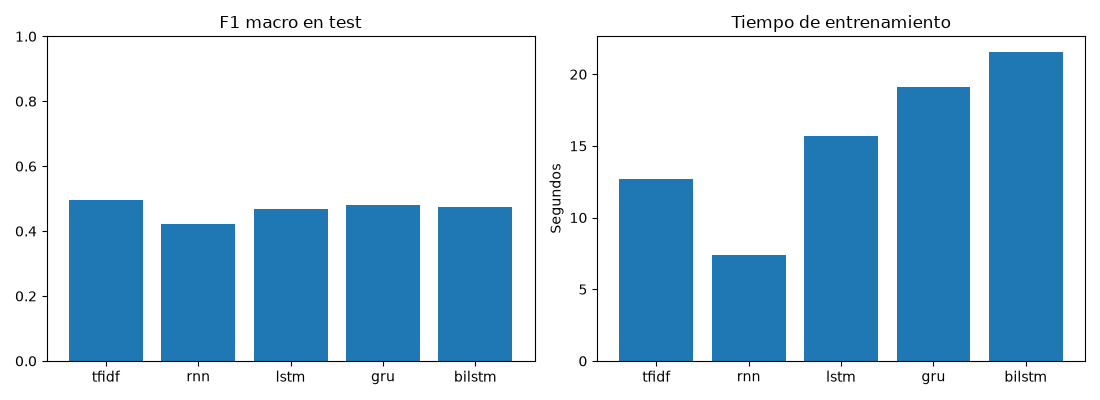

**Seleccionado con validación: TFIDF.**

Accuracy de siempre elegir la clase mayoritaria de train: 0.201


,modelo,accuracy,precision_macro,recall_macro,f1_macro,log_loss,mae_estrellas,error_dos_o_mas,segundos_entrenamiento,parametros,epocas
0,tfidf,0.5005,0.4918,0.5008,0.4944,1.1895,0.6636,0.1219,12.7273,150005,0


In [11]:
display(Image(filename=str(OUT / 'comparacion.png')))
seleccion = json.loads((OUT / 'seleccion.json').read_text(encoding='utf-8'))['modelo']
referencia = json.loads((OUT / 'referencia_mayoritaria.json').read_text())
display(Markdown(f'**Seleccionado con validación: {seleccion.upper()}.**'))
print('Accuracy de siempre elegir la clase mayoritaria de train:', round(referencia['accuracy'],3))
display(metricas[metricas.modelo.eq(seleccion)].round(4))


## 11. Curvas: aprender no es memorizar

Una pérdida que baja en train y validación sugiere aprendizaje útil. Si solo mejora train,
puede existir sobreajuste. Si ambos conjuntos siguen mal, puede faltar entrenamiento,
capacidad o una representación adecuada. La evolución importa tanto como el último punto.
La comparación usa una sola semilla: diferencias pequeñas requieren repeticiones antes
de declararse concluyentes.


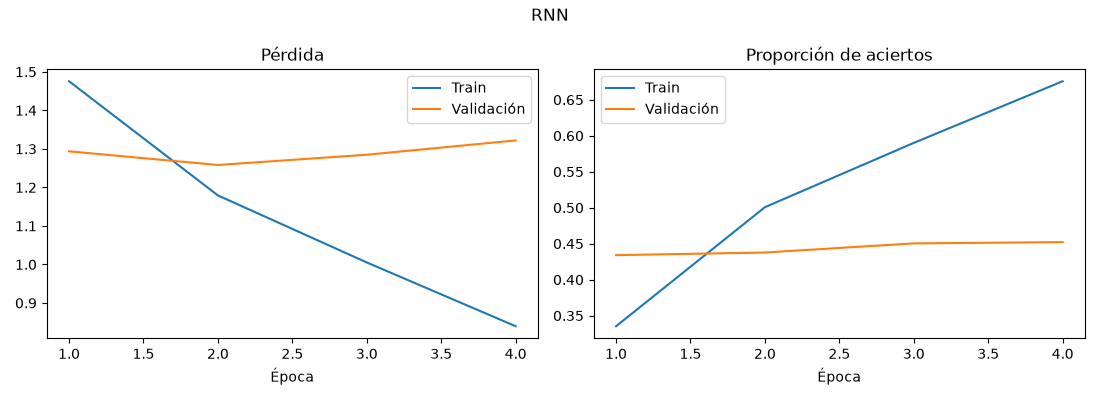

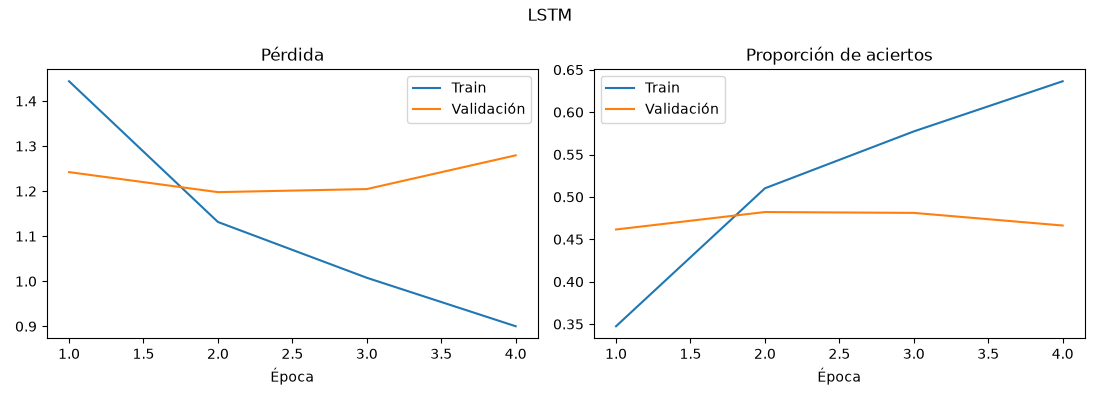

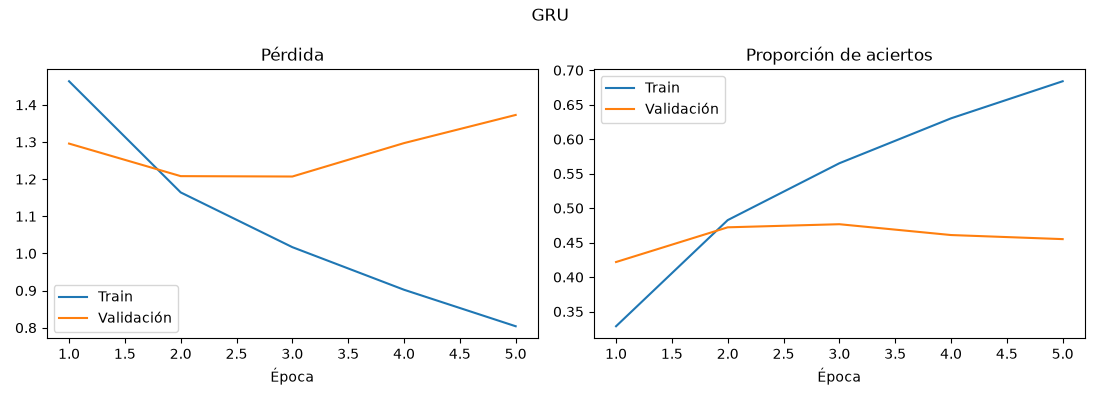

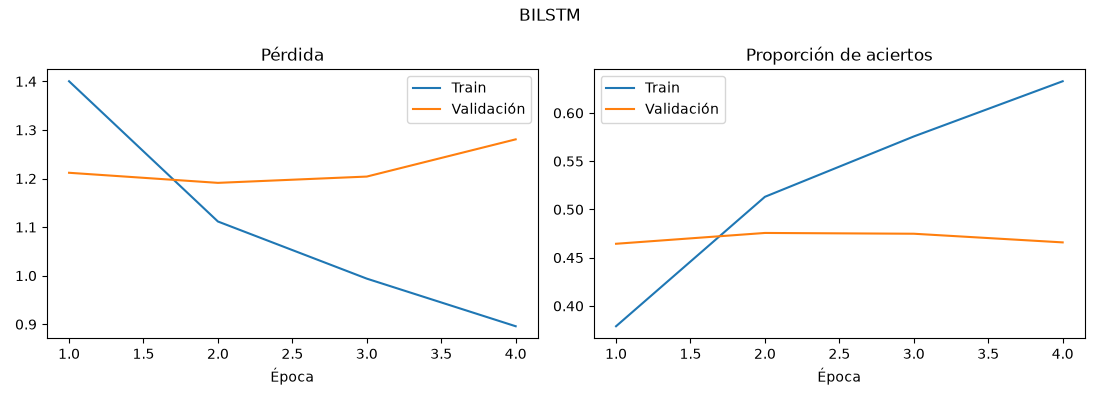

In [12]:
for nombre in ['rnn','lstm','gru','bilstm']:
    display(Image(filename=str(OUT / f'curvas_{nombre}.png')))


## 12. ¿Dónde se equivoca el modelo elegido?

En la matriz, filas son estrellas reales y columnas predichas. La diagonal contiene
aciertos. Los errores próximos a ella confunden calificaciones vecinas; las esquinas
opuestas representan errores grandes. No asumimos de antemano que las clases intermedias
sean peores: lo comprobamos con el recall y F1 de cada una.

La tabla de errores muestra reseñas reales de test, su etiqueta y la predicción.
Ordenamos por magnitud del error y probabilidad máxima para revisar fallos importantes.
Estos ejemplos son una selección ilustrativa, no una muestra representativa de todos los errores.


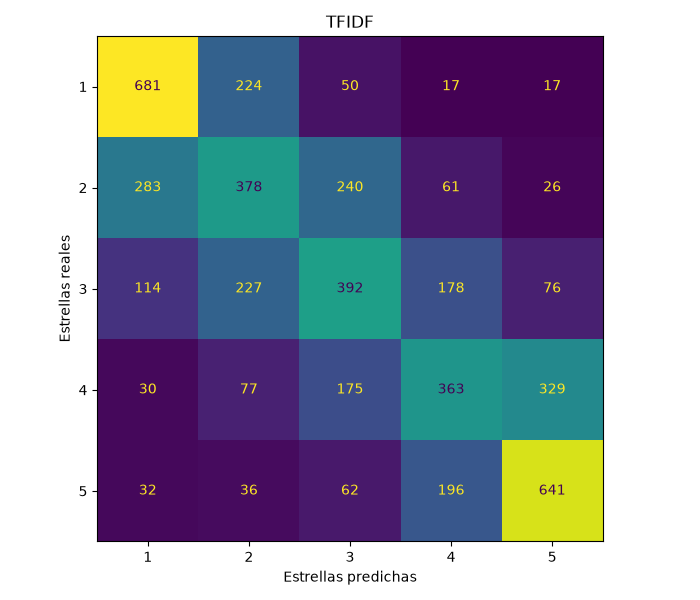

,precision,recall,f1-score,support
1 estrellas,0.597,0.689,0.640,989.000
2 estrellas,0.401,0.383,0.392,988.000
3 estrellas,0.427,0.397,0.411,987.000
4 estrellas,0.445,0.373,0.406,974.000
5 estrellas,0.589,0.663,0.624,967.000
accuracy,0.501,0.501,0.501,0.501
macro avg,0.492,0.501,0.494,4905.000
weighted avg,0.492,0.501,0.494,4905.000


,text,estrellas,prediccion,error_absoluto,probabilidad_maxima
0,"No llegó el paquete, informé al vendedor y tuve respuesta inmediata para darme solución.",5,1,4,0.575997
1,"El material no es de muy buena calidad. el pedido tardo mucho ,no estoy muy contento con esta compra,no lo recomiendo",1,5,4,0.530801
2,Me han gustado mucho per estoy descontenta porque de 2 que pedi en diferente tiempo solo he recibido 1,5,1,4,0.509909
3,Producto y envío correctos. Nada que objetar.,5,1,4,0.432464
4,Siempre he comprado WD y no me defrauda. Desafortunadamente no puedo decir lo mismo cuando he comprado otras marcas,5,1,4,0.396027
5,Magnífico! es el tercero que compro porque por error... lo tiramos a la basura!!,5,1,4,0.383074
6,"EL PRODUCTO ME ENCANTA, PERO ME HAN MANDADO MEDIDA DIFERENTE A LA QUE PEDI; TENGO QUE DEVOLVERLO, PERO MUCHÍSIMA AMABILIDAD POR PARTE DE AMAZON",5,1,4,0.374343
7,"a los dos días de estar usando el aceite ya se notan los resultados. Yo lo he utilizado para cicatriz de una operación de tiroides y ya casi ni se nota. Por la noche la utilizo en la cara y las manchas que tenía cada vez están más claras. Una maravilla, lo recomiendo.",5,1,4,0.373883
8,"De las mejores compras que he hecho. Lógicamente no es un fisio.. Pero doy fe que ayuda muchísimo en el día a día. Tanto yo como mi pareja, por el trabajo, sufrimos de cervicales y espalda, todas las noches lo usamos y notamos un gran mejoría. Antes teníamos que ir básicamente una vez a la seman...",5,1,4,0.373670
9,"Llevo varios cristales templados para Iphone 7, (el mío y el de mi pareja) y este, sin duda, es el peor que he visto nunca. Queda más espacio despegado que pegado. Te lleva una hora el intento de reducir las marcas que deja y no terminan de quitarse nunca. El precio excesivo para la calidad que ...",1,5,4,0.368478


In [13]:
display(Image(filename=str(OUT / f'matriz_{seleccion}.png')))
display(pd.read_csv(OUT / f'reporte_{seleccion}.csv',index_col=0).round(3))
errores = pd.read_csv(OUT / f'errores_{seleccion}.csv')
with pd.option_context('display.max_colwidth', 300):
    display(errores[['text','estrellas','prediccion','error_absoluto','probabilidad_maxima']].head(10))


## 13. Longitud, negaciones y pistas explícitas

Las reseñas se agrupan por longitud. También se evalúan las que contienen palabras de
negación y las que mencionan estrellas. Los grupos se superponen y se muestran sus tamaños.
Una diferencia entre ellos es descriptiva: no prueba que la negación cause el error ni
que el modelo haya comprendido el contexto. Las clases pueden distribuirse distinto por grupo.


In [14]:
segmentos = pd.read_csv(OUT / 'segmentos.csv')
display(segmentos[segmentos.modelo.eq(seleccion)].round(3))
display(segmentos.pivot(index='modelo',columns='segmento',values='accuracy').round(3))


,modelo,segmento,n,accuracy,mae_estrellas
0,tfidf,cortas_hasta_20,2109,0.497,0.675
1,tfidf,medias_21_a_60,2423,0.510,0.640
2,tfidf,largas_mas_60,373,0.456,0.751
3,tfidf,con_negacion,2605,0.501,0.671
4,tfidf,menciona_estrellas,108,0.639,0.463


segmento,con_negacion,cortas_hasta_20,largas_mas_60,medias_21_a_60,menciona_estrellas
modelo,,,,,
bilstm,0.493,0.495,0.475,0.492,0.472
gru,0.480,0.483,0.434,0.483,0.481
lstm,0.486,0.491,0.453,0.489,0.417
rnn,0.450,0.469,0.394,0.460,0.343
tfidf,0.501,0.497,0.456,0.510,0.639


### 13.1 Robustez: controles y perturbaciones de reseñas reales

Robustez es mantener un comportamiento útil ante variaciones de entrada. La medimos en una muestra estratificada de **200 reseñas de test (40 por estrella, semilla 42)**, sin reentrenar ni cambiar el modelo elegido. El archivo original está ordenado por clase: tomar sus primeras filas sesgaría la prueba. Publicamos tamaño, distribución, accuracy, F1 macro y porcentaje de predicciones que cambian respecto al original de la misma muestra.

- **Mayúsculas y espacios adicionales:** deben dar exactamente el mismo texto limpio. Es una prueba de invariancia del preprocesamiento, no evidencia de comprensión.
- **Quitar tildes:** simula escritura informal. Puede alterar significado («sí/si»); conservar la etiqueta es una aproximación que debe revisarse.
- **Una errata por reseña:** intercambia dos letras internas de la primera palabra de al menos seis caracteres. Puede crear OOV; no representa todas las erratas reales. Algunas reseñas quedan sin cambios si no tienen una palabra elegible.

Las versiones perturbadas son copias de prueba explícitamente modificadas, **no datos nuevos ni sintéticos usados para entrenar**. Una caída describe sensibilidad en esta muestra, no causalidad ni desempeño en otras tiendas. No hay validación externa ni múltiples semillas. No volveremos a ajustar con estos resultados.


In [15]:
# Muestra fija: comparación pareada antes/después con los mismos modelos guardados.
import unicodedata
por_clase = min(40, int(test.label.value_counts().min()))
sonda = test.groupby('label', group_keys=False).sample(n=por_clase, random_state=42).sort_values('id').copy()
display(sonda.estrellas.value_counts().sort_index().rename('reseñas_por_estrella'))
assert sonda.label.nunique() == 5
def sin_tildes(t):
    return ''.join(c for c in unicodedata.normalize('NFD', t) if unicodedata.category(c) != 'Mn')
def una_errata(t):
    palabras = t.split()
    for i, palabra in enumerate(palabras):
        if len(palabra) >= 6:
            palabras[i] = palabra[:2] + palabra[3] + palabra[2] + palabra[4:]
            break
    return ' '.join(palabras)
originales = sonda.texto_limpio.tolist()
variantes = {
    'original': originales,
    'mayusculas_espacios': [limpiar('   '.join(t.upper().split())) for t in originales],
    'sin_tildes': [limpiar(sin_tildes(t)) for t in originales],
    'una_errata': [limpiar(una_errata(t)) for t in originales]}
assert variantes['mayusculas_espacios'] == originales
baseline_guardado = joblib.load(OUT / 'tfidf.joblib')
robustez_filas = []
for nombre in ['tfidf', 'rnn', 'lstm', 'gru', 'bilstm']:
    pred_original = None
    for variante, textos in variantes.items():
        probs = (baseline_guardado.predict_proba(textos) if nombre == 'tfidf' else
            redes_auditadas[nombre].predict(vector_auditoria(tf.constant(textos)), verbose=0))
        pred = probs.argmax(1)
        if variante == 'original':
            pred_original = pred.copy()
        cambios = float(np.mean(pred != pred_original))
        if variante == 'mayusculas_espacios':
            assert cambios == 0
        robustez_filas.append({'modelo': nombre, 'variante': variante, 'n': len(sonda),
            'fraccion_textos_modificados': float(np.mean([a != b for a, b in zip(textos, originales)])),
            'fraccion_predicciones_cambiadas': cambios, **medir(sonda.label, probs)})
robustez = pd.DataFrame(robustez_filas)
robustez['delta_f1_vs_original'] = robustez.apply(lambda r: r.f1_macro -
    robustez.loc[robustez.modelo.eq(r.modelo) & robustez.variante.eq('original'), 'f1_macro'].iloc[0], axis=1)
display(robustez[['modelo','variante','n','fraccion_textos_modificados','accuracy','f1_macro',
    'delta_f1_vs_original','fraccion_predicciones_cambiadas']].round(4))
robustez.to_csv(OUT / 'robustez.csv', index=False)


estrellas
1    40
2    40
3    40
4    40
5    40
Name: reseñas_por_estrella, dtype: int64

,modelo,variante,n,fraccion_textos_modificados,accuracy,f1_macro,delta_f1_vs_original,fraccion_predicciones_cambiadas
0,tfidf,original,200,0.000,0.545,0.5338,0.0000,0.000
1,tfidf,mayusculas_espacios,200,0.000,0.545,0.5338,0.0000,0.000
2,tfidf,sin_tildes,200,0.735,0.545,0.5283,-0.0055,0.095
3,tfidf,una_errata,200,0.995,0.520,0.5096,-0.0243,0.100
4,rnn,original,200,0.000,0.500,0.4583,0.0000,0.000
5,rnn,mayusculas_espacios,200,0.000,0.500,0.4583,0.0000,0.000
6,rnn,sin_tildes,200,0.735,0.455,0.4106,-0.0477,0.115
7,rnn,una_errata,200,0.995,0.500,0.4622,0.0039,0.140
8,lstm,original,200,0.000,0.515,0.4817,0.0000,0.000
9,lstm,mayusculas_espacios,200,0.000,0.515,0.4817,0.0000,0.000


## 14. Reutilizar el modelo sin volver a entrenarlo

Recargamos el modelo elegido y clasificamos tres reseñas reales de test. Este paso comprueba
que los archivos guardados funcionan. No es una evaluación nueva ni una validación externa:
esas filas ya forman parte de la prueba presentada.


In [16]:
muestra = test.head(3)
recarga = predecir(muestra.text.to_list(), OUT)
recarga['estrellas_reales'] = muestra.estrellas.to_numpy()
display(recarga)
# El modelo guardado debe reproducir las etiquetas obtenidas antes de guardarlo.
assert recarga.estrellas_predichas.tolist() == predicciones[seleccion].head(3).prediccion.tolist()


,texto,estrellas_predichas,probabilidad_maxima,estrellas_reales
0,no me llego el articulo me lo mando por correo...,1,0.783438,1
1,"la mensajería horrible, no compro mas",1,0.367138,1
2,Estoy muy decepcionado con el vendedor ya que ...,1,0.811398,1


## 15. Conclusiones del experimento y uso posible

El siguiente resumen se calcula con los resultados de esta ejecución. Evita atribuir
superioridad a una arquitectura antes de observar la comparación.


In [17]:
fila = metricas.set_index('modelo').loc[seleccion]
base = metricas.set_index('modelo').loc['tfidf']
display(Markdown(
    f"El modelo seleccionado por validación fue **{seleccion.upper()}**. En test obtuvo "
    f"**F1 macro {fila.f1_macro:.3f}**, **accuracy {fila.accuracy:.1%}** y un error "
    f"absoluto medio de **{fila.mae_estrellas:.2f} estrellas**. "
    f"Su diferencia de F1 frente a TF-IDF fue **{fila.f1_macro-base.f1_macro:+.3f}**. "
    "Estos resultados corresponden a esta muestra, limpieza y presupuesto; no son una "
    "garantía de desempeño con nuevas tiendas, productos o períodos."))


El modelo seleccionado por validación fue **TFIDF**. En test obtuvo **F1 macro 0.494**, **accuracy 50.1%** y un error absoluto medio de **0.66 estrellas**. Su diferencia de F1 frente a TF-IDF fue **+0.000**. Estos resultados corresponden a esta muestra, limpieza y presupuesto; no son una garantía de desempeño con nuevas tiendas, productos o períodos.

In [18]:
# Síntesis vinculada a los resultados: no presupone que gane una red.
tabla = metricas.set_index('modelo')
comparacion_recurrentes = tabla.loc[['rnn','lstm','gru','bilstm'],
    ['f1_macro','accuracy','precision_macro','recall_macro','mae_estrellas','segundos_entrenamiento','parametros']].copy()
comparacion_recurrentes['delta_f1_vs_tfidf'] = comparacion_recurrentes.f1_macro - tabla.loc['tfidf','f1_macro']
display(comparacion_recurrentes.round(4))
reporte = pd.read_csv(OUT / f'reporte_{seleccion}.csv', index_col=0).iloc[:5]
clase_debil = reporte['f1-score'].idxmin()
segmento_debil = segmentos[segmentos.modelo.eq(seleccion)].sort_values('accuracy').iloc[0]
perturbaciones = robustez[robustez.modelo.eq(seleccion) & robustez.variante.isin(['sin_tildes','una_errata'])]
peor_perturbacion = perturbaciones.sort_values('delta_f1_vs_original').iloc[0]
display(Markdown(
    f"**Errores:** la clase con menor F1 fue **{clase_debil}** "
    f"({reporte.loc[clase_debil, 'f1-score']:.3f}); el **{tabla.loc[seleccion, 'error_dos_o_mas']:.1%}** "
    "de test presentó un error de al menos dos estrellas. "
    f"Entre los segmentos definidos, **{segmento_debil.segmento}** tuvo la menor accuracy "
    f"({segmento_debil.accuracy:.1%}, n={int(segmento_debil.n)}). "
    "Los grupos se superponen y no tienen necesariamente la misma distribución de clases.\n\n"
    f"**Robustez:** en la muestra de {len(sonda)} reseñas, la menor variación de F1 entre las dos "
    f"perturbaciones se observó en **{peor_perturbacion.variante}**: "
    f"{peor_perturbacion.delta_f1_vs_original:+.3f}. "
    "El control de espacios/mayúsculas y la invariancia a PAD verifican implementación; "
    "no equivalen a una validación fuera del dominio.\n\n"
    "**Decisión:** conservar el modelo elegido por validación como referencia de este laboratorio. "
    "Antes de automatizar decisiones, revisar los errores graves, evaluar nuevos productos/periodos, "
    "repetir semillas y calibrar probabilidades. No se debe afirmar que una arquitectura gana universalmente."))


,f1_macro,accuracy,precision_macro,recall_macro,mae_estrellas,segundos_entrenamiento,parametros,delta_f1_vs_tfidf
modelo,,,,,,,,
rnn,0.4229,0.4591,0.4406,0.4598,0.7957,7.3769,482245,-0.0715
lstm,0.4690,0.4875,0.4687,0.4878,0.6899,15.7149,488485,-0.0254
gru,0.4806,0.4795,0.4826,0.4795,0.6663,19.0914,486501,-0.0138
bilstm,0.4749,0.4915,0.4720,0.4920,0.6832,21.5669,496965,-0.0195


**Errores:** la clase con menor F1 fue **2 estrellas** (0.392); el **12.2%** de test presentó un error de al menos dos estrellas. Entre los segmentos definidos, **largas_mas_60** tuvo la menor accuracy (45.6%, n=373). Los grupos se superponen y no tienen necesariamente la misma distribución de clases.

**Robustez:** en la muestra de 200 reseñas, la menor variación de F1 entre las dos perturbaciones se observó en **una_errata**: -0.024. El control de espacios/mayúsculas y la invariancia a PAD verifican implementación; no equivalen a una validación fuera del dominio.

**Decisión:** conservar el modelo elegido por validación como referencia de este laboratorio. Antes de automatizar decisiones, revisar los errores graves, evaluar nuevos productos/periodos, repetir semillas y calibrar probabilidades. No se debe afirmar que una arquitectura gana universalmente.

**Aplicación posible:** organizar reseñas sin calificación o ayudar a revisar opiniones
en atención al cliente. En Amazon la estrella ya existe; la utilidad del laboratorio es
aprender a estimarla desde el lenguaje y entender cuándo falla. No sustituye la opinión
del cliente ni identifica automáticamente el motivo de una queja.

**Qué falta para uso real:** validación externa, análisis por producto/cliente cuando se
disponga de esos datos, calibración y revisión de errores costosos. Haría falta repetir
semillas o estimar intervalos antes de interpretar diferencias pequeñas. Los textos
ambiguos retirados y los duplicados cercanos no resueltos limitan la generalización.

**Preguntas para presentar:** ¿la mejora justifica el tiempo?, ¿qué estrellas se confunden?,
¿qué se pierde al truncar?, ¿el modelo funciona peor cuando no se menciona una calificación?,
¿qué errores requerirían revisión humana? No se ha afirmado comprensión profunda de
ironía, causas ni emociones: el objetivo medido son cinco calificaciones.

**Fuentes y reproducibilidad:**
- [Repositorio del dataset](https://huggingface.co/datasets/SetFit/amazon_reviews_multi_es).
- El script original descargado en `amazon_reviews_es/datos_amazon/create_dataset.py` se conserva como evidencia de la
  transformación de estrellas a etiquetas; no se ejecuta.
- `amazon_reviews_es/datos_amazon/procedencia.json` contiene revisión y hashes; `auditoria.json`, las exclusiones.
- `amazon_reviews_es/resultados_amazon/` contiene particiones, configuración, métricas, predicciones y modelos.
- Revise las condiciones del corpus original antes de redistribuir los textos.


**Documentación técnica consultada:** [TextVectorization](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/), [masking y padding](https://www.tensorflow.org/guide/keras/understanding_masking_and_padding), [Embedding](https://keras.io/api/layers/core_layers/embedding/), [SimpleRNN](https://keras.io/api/layers/recurrent_layers/simple_rnn/). Las tablas y diagnósticos del laboratorio se calculan con el código y los datos declarados.
